<a href="https://colab.research.google.com/github/rwalden-gif/IntroToML/blob/main/Homework4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_squared_error, r2_score

url = 'https://raw.githubusercontent.com/rwalden-gif/IntroToML/main/Cancer.csv'
cancer = pd.read_csv(url)
cancer = cancer.drop(columns=["Unnamed: 32", "id"])

Xc = cancer.drop(columns=["diagnosis"]).values
Yc = (cancer["diagnosis"] == "M").astype(int).values

Xc_train, Xc_test, Yc_train, Yc_test = train_test_split(Xc, Yc, test_size=0.2, random_state=42, stratify=Yc)

scaler_c = StandardScaler()
Xc_train = scaler_c.fit_transform(Xc_train)
Xc_test = scaler_c.transform(Xc_test)

print("Training samples:", len(Yc_train))
print("Test samples:", len(Yc_test))


Training samples: 455
Test samples: 114


In [6]:
kernels = ["linear", "rbf", "poly"]
results_svm = {}
best_kernel, best_f1 = None, None

for k in kernels:
    model = SVC(kernel=k, random_state=42)
    model.fit(Xc_train, Yc_train)
    pred = model.predict(Xc_test)

    acc = accuracy_score(Yc_test, pred)
    prec = precision_score(Yc_test, pred)
    rec = recall_score(Yc_test, pred)
    f1 = f1_score(Yc_test, pred)
    results_svm[k] = (acc, prec, rec, f1)
    print(f"{k}: accuracy={acc:.4f}, precision={prec:.4f}, recall={rec:.4f}, f1={f1:.4f}")

    if best_f1 is None or f1 > best_f1:
        best_kernel, best_f1 = k, f1

print("Best kernel:", best_kernel)

linear: accuracy=0.9649, precision=1.0000, recall=0.9048, f1=0.9500
rbf: accuracy=0.9737, precision=1.0000, recall=0.9286, f1=0.9630
poly: accuracy=0.8860, precision=1.0000, recall=0.6905, f1=0.8169
Best kernel: rbf


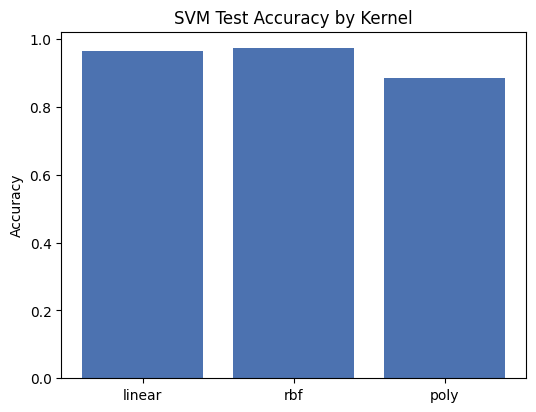

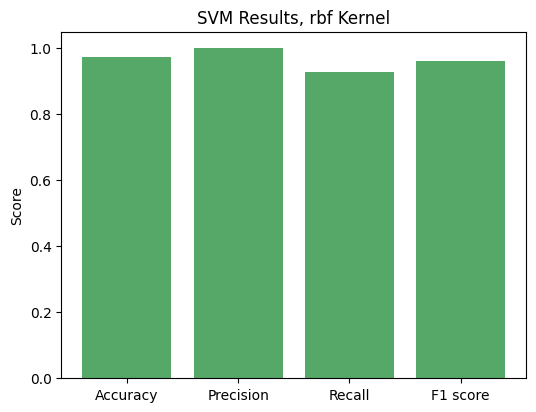

In [7]:
plt.figure(figsize=(6,4.5))
plt.bar(results_svm.keys(), [v[0] for v in results_svm.values()], color="#4C72B0")
plt.ylabel("Accuracy")
plt.title("SVM Test Accuracy by Kernel")
plt.show()

acc, prec, rec, f1 = results_svm[best_kernel]
plt.figure(figsize=(6,4.5))
plt.bar(["Accuracy", "Precision", "Recall", "F1 score"], [acc, prec, rec, f1], color="#55A868")
plt.ylabel("Score")
plt.title(f"SVM Results, {best_kernel} Kernel")
plt.show()

In [8]:
url_2 = 'https://raw.githubusercontent.com/rwalden-gif/IntroToML/main/Housing.csv'
housing = pd.read_csv(url_2)

yes_no_cols = ["mainroad", "guestroom", "basement", "hotwaterheating", "airconditioning", "prefarea"]
for c in yes_no_cols:
    housing[c] = (housing[c] == "yes").astype(int)

features = ["area", "bedrooms", "bathrooms", "stories", "mainroad", "guestroom",
            "basement", "hotwaterheating", "airconditioning", "parking", "prefarea"]

Xh = housing[features].values.astype(float)
Yh = housing["price"].values.astype(float)

Xh_train, Xh_test, Yh_train, Yh_test = train_test_split(Xh, Yh, test_size=0.2, random_state=42)

scaler_x = StandardScaler().fit(Xh_train)
Xh_train = scaler_x.transform(Xh_train)
Xh_test = scaler_x.transform(Xh_test)

scaler_y = StandardScaler().fit(Yh_train.reshape(-1, 1))
Yh_train_scaled = scaler_y.transform(Yh_train.reshape(-1, 1)).ravel()

print("Training samples:", len(Yh_train))
print("Test samples:", len(Yh_test))

Training samples: 436
Test samples: 109


In [9]:
kernels = ["linear", "rbf", "poly"]
results_svr = {}
best_kernel_svr, best_r2 = None, None

for k in kernels:
    model = SVR(kernel=k)
    model.fit(Xh_train, Yh_train_scaled)
    pred_scaled = model.predict(Xh_test)
    pred = scaler_y.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()

    mse = mean_squared_error(Yh_test, pred)
    r2 = r2_score(Yh_test, pred)
    results_svr[k] = (mse, r2, pred)
    print(f"{k}: mse={mse:.4e}, r2={r2:.4f}")

    if best_r2 is None or r2 > best_r2:
        best_kernel_svr, best_r2 = k, r2

print("Best kernel:", best_kernel_svr)

linear: mse=1.9309e+12, r2=0.6180
rbf: mse=2.0372e+12, r2=0.5970
poly: mse=2.3175e+12, r2=0.5415
Best kernel: linear


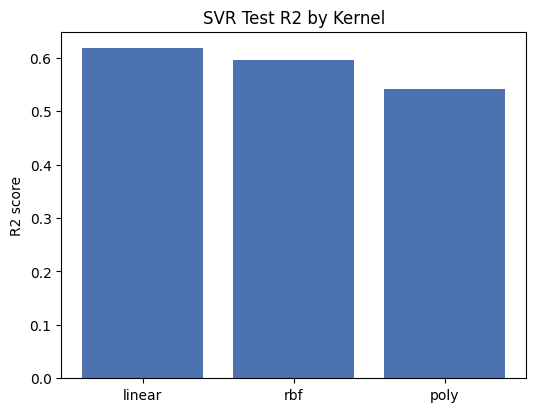

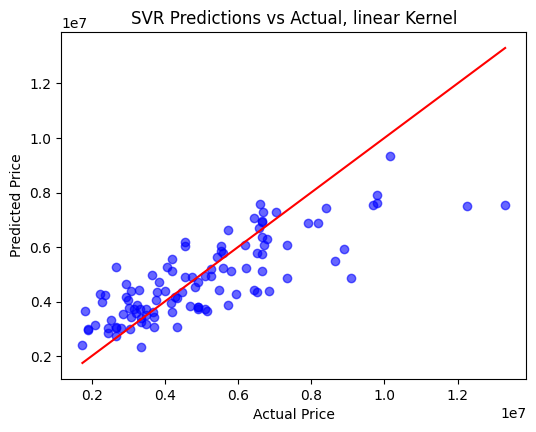

In [10]:
plt.figure(figsize=(6,4.5))
plt.bar(results_svr.keys(), [v[1] for v in results_svr.values()], color="#4C72B0")
plt.ylabel("R2 score")
plt.title("SVR Test R2 by Kernel")
plt.show()

best_pred = results_svr[best_kernel_svr][2]
plt.figure(figsize=(6,4.5))
plt.scatter(Yh_test, best_pred, color="blue", alpha=0.6)
lims = [min(Yh_test.min(), best_pred.min()), max(Yh_test.max(), best_pred.max())]
plt.plot(lims, lims, color="red")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"SVR Predictions vs Actual, {best_kernel_svr} Kernel")
plt.show()